In [1]:
import pandas as pd

df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [14]:
df.shape

(1879893, 9)

PART 1: Analyzing Best-Seller Trends Across Product Categories

Objective: Understand the relationship between product categories and their best-seller status.

1. Crosstab Analysis:

- Create a crosstab between the product category and the isBestSeller status.

- Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [7]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result = crosstab_result.sort_values(by=True, ascending=False)
crosstab_result.head(10)

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
Beauty,19010,302
Pet Supplies,9152,285
Arts & Crafts,9319,230
Women,17559,213


2. Statistical Tests:

- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [8]:
from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_p_value

np.float64(0.0)

3. Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Axes: xlabel='category'>

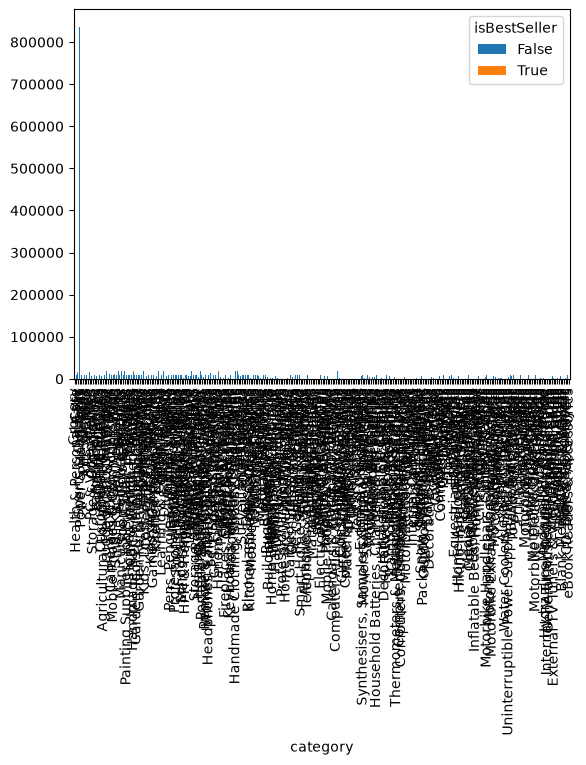

In [9]:
crosstab_result.plot(kind="bar", stacked=True)

PART 2: Exploring Product Prices and Ratings Across Categories and Brands

Objective: Investigate how different product categories influence product prices.

0. Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [13]:
def remove_outliers_tukey(df, column_name):
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df_filtered = df[(df[column_name] >= lower_bound) & (df[column_name] <= upper_bound)]
    
    return df_filtered

df = remove_outliers_tukey(df, 'price')

(1879893, 9)

1. Violin Plots:

- Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
  
- Which product category tends to have the highest median price? Don't filter here by top categories.

C:\Users\pablo\AppData\Local\Temp\ipykernel_9296\898941212.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='price', y='category', palette='muted')


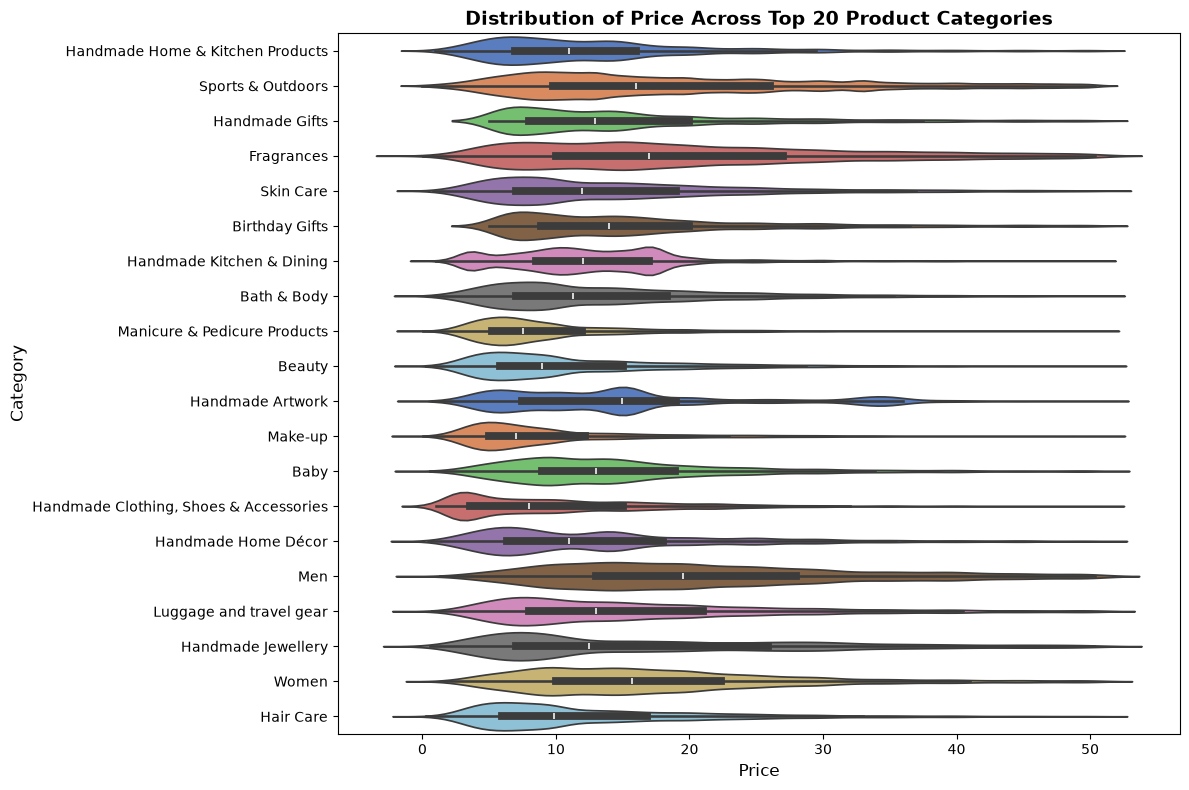

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

top_20_categories = df['category'].value_counts().head(20).index
df_top20 = df[df['category'].isin(top_20_categories)]

plt.figure(figsize=(12, 8))
sns.violinplot(data=df_top20, x='price', y='category', palette='muted')

plt.title('Distribution of Price Across Top 20 Product Categories', fontsize=14, fontweight='bold')
plt.xlabel('Price', fontsize=12)
plt.ylabel('Category', fontsize=12)

plt.tight_layout()
plt.show()

In [21]:
median_prices = df.groupby('category')['price'].median()

highest_median_category = median_prices.idxmax()
highest_median_value = median_prices.max()

print(f"Category with the highest median price: '{highest_median_category}'")
print(f"Median Price: {highest_median_value:.2f}")

Category with the highest median price: 'Hockey Shoes'
Median Price: 44.55


2. Bar Charts:

- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

- Which product category commands the highest average price? Don't filter here by top categories.

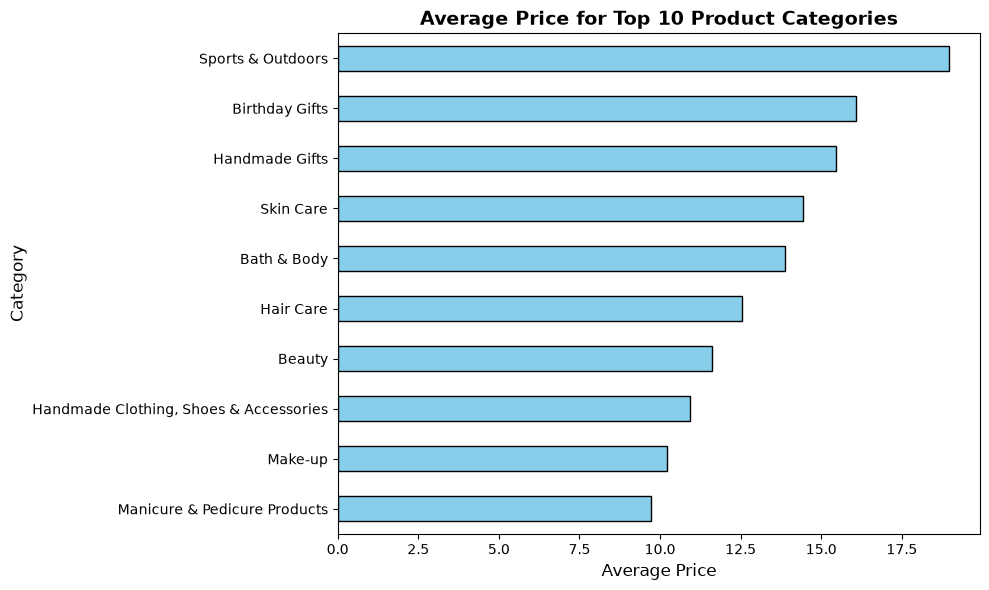

In [23]:
top_10_categories = df['category'].value_counts().head(10).index
df_top10 = df[df['category'].isin(top_10_categories)]

avg_prices = df_top10.groupby('category')['price'].mean().sort_values(ascending=True)

plt.figure(figsize=(10, 6))
avg_prices.plot(kind='barh', color='skyblue', edgecolor='black')

plt.title('Average Price for Top 10 Product Categories', fontsize=14, fontweight='bold')
plt.xlabel('Average Price', fontsize=12)
plt.ylabel('Category', fontsize=12)

plt.tight_layout()
plt.show()

In [24]:
mean_prices = df.groupby('category')['price'].mean()

highest_avg_category = mean_prices.idxmax()
highest_avg_value = mean_prices.max()

print(f"Category with the highest average price: '{highest_avg_category}'")
print(f"Average Price: {highest_avg_value:.2f}")

Category with the highest average price: 'Hockey Shoes'
Average Price: 41.13


3. Box Plots:

- Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
  
- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

C:\Users\pablo\AppData\Local\Temp\ipykernel_9296\3573630522.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x='stars', y='category', palette='Set2')


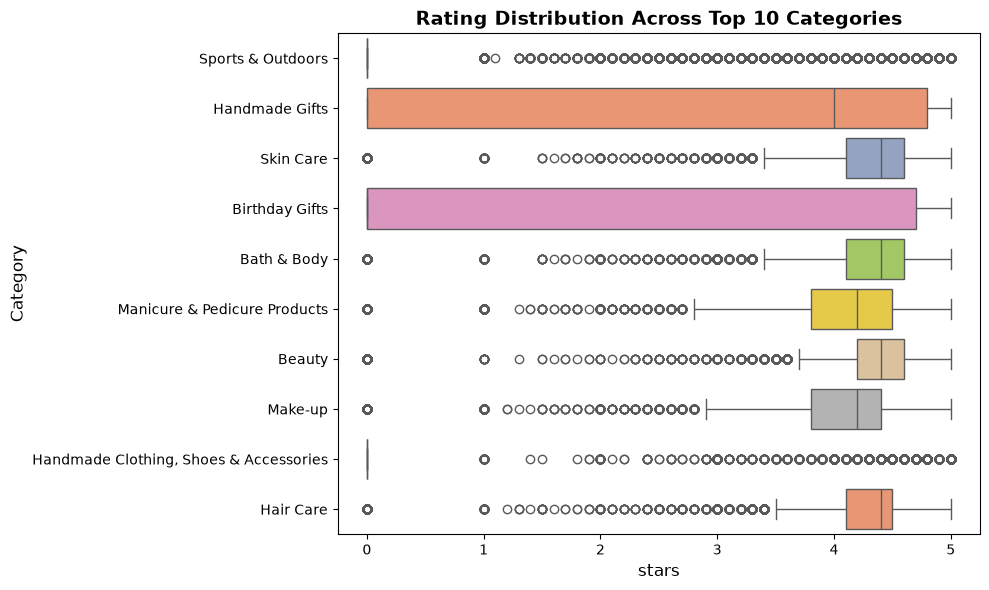

In [28]:
top_10_categories = df['category'].value_counts().head(10).index
df_top10 = df[df['category'].isin(top_10_categories)]

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_top10, x='stars', y='category', palette='Set2')

plt.title('Rating Distribution Across Top 10 Categories', fontsize=14, fontweight='bold')
plt.xlabel('stars', fontsize=12)
plt.ylabel('Category', fontsize=12)

plt.tight_layout()
plt.show()

In [31]:
median_ratings = df.groupby('category')['stars'].median()

highest_rating_category = median_ratings.idxmax()
highest_rating_value = median_ratings.max()

print(f"Category with the highest median rating: '{highest_rating_category}'")
print(f"Median Rating: {highest_rating_value:.2f}")

Category with the highest median rating: 'Beer, Wine & Spirits'
Median Rating: 4.60


PART 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

1. Correlation Coefficients:

- Calculate the correlation coefficient between price and stars.
  
- Is there a significant correlation between product price and its rating?

In [33]:
correlation_coefficient = df['price'].corr(df['stars'])

correlation_coefficient 

np.float64(-0.047719022825311284)

In [ ]:
# There is no significant correlation between stars and price.

2. Visualizations:

- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
  
- Use a correlation heatmap to visualize correlations between all numerical variables.

<Axes: xlabel='stars', ylabel='price'>

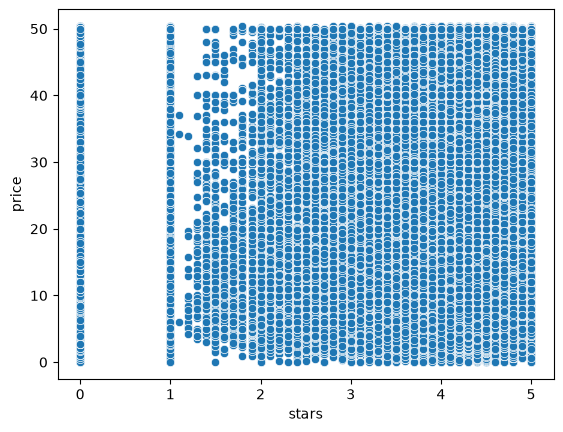

In [34]:
sns.scatterplot(data=df, x='stars', y='price')

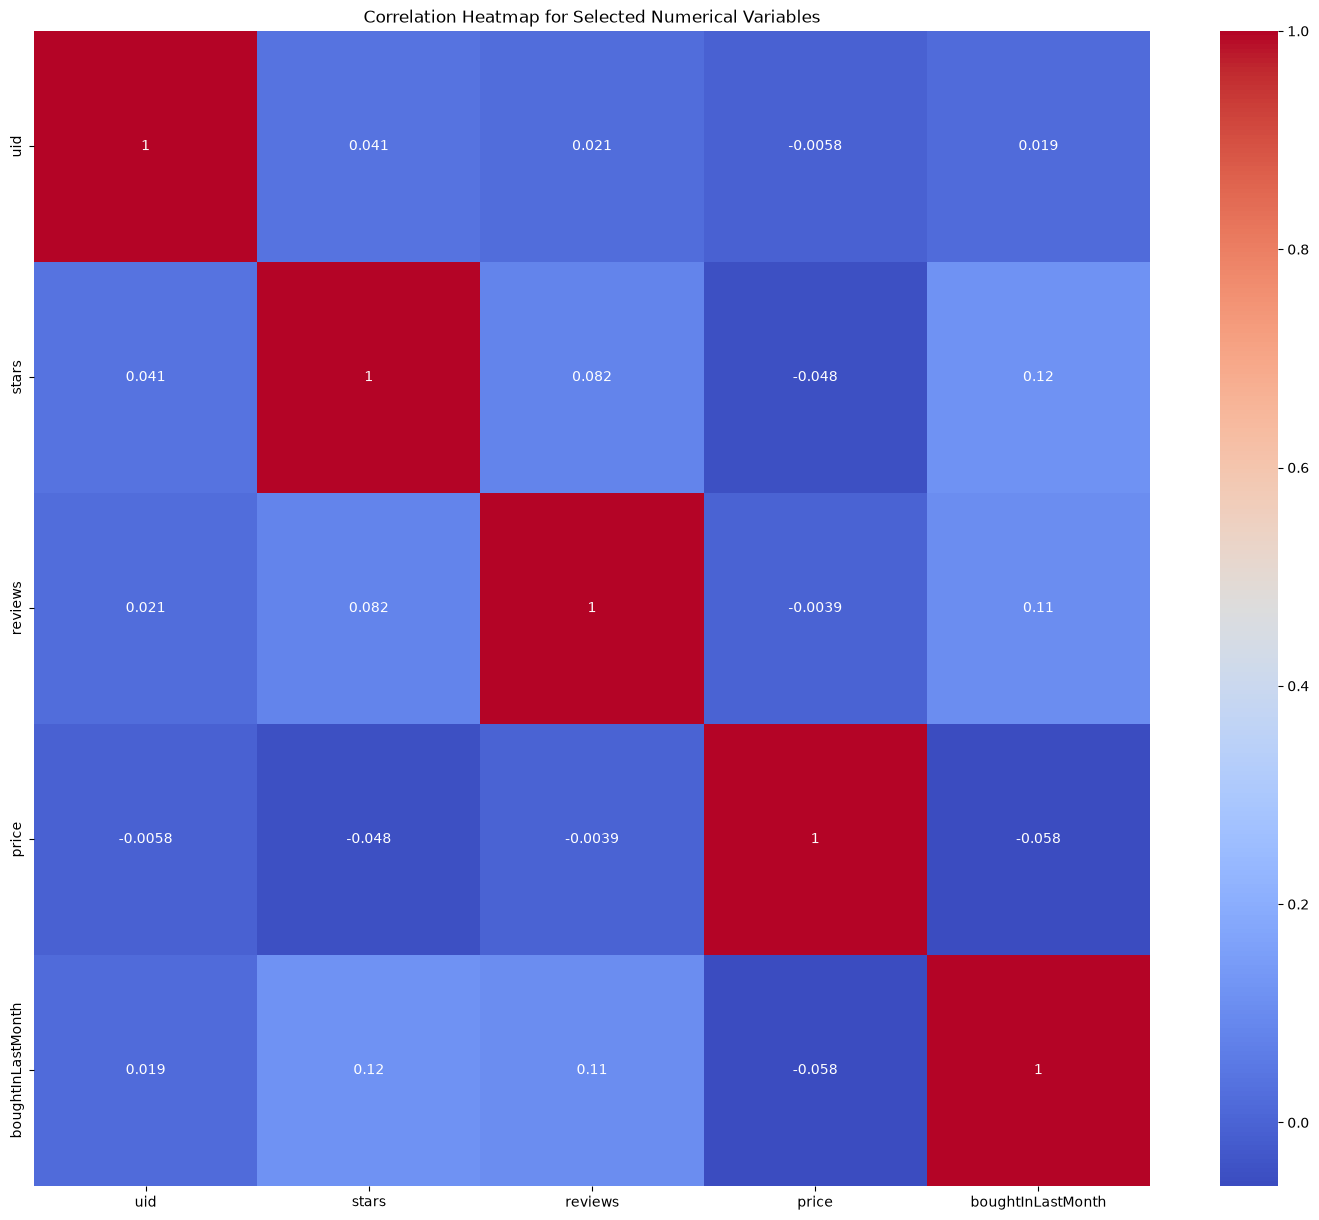

In [38]:
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 5]

df_numerical = df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

correlation_matrix = df_numerical.corr()

plt.figure(figsize=(18, 15))

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()